# 01 · Exploración de datos

Primer vistazo a `jugadores_procesados.csv` (salida de `src/data/make_dataset.py`).

Preguntas que queremos responder antes de modelar:

1. ¿Qué tan balanceadas están las 4 clases del Nivel 1?
2. ¿Los nulos rellenados con 0 son realmente estructurales (porteros vs. jugadores de campo)?
3. ¿Qué métricas distinguen a cada posición?
4. ¿Qué tan correlacionadas están las métricas entre sí?
5. ¿Se separan visualmente las clases? (anticipo de PCA vs. Fisher)

In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

sns.set_theme(style="whitegrid")

DATA = Path("..") / "data" / "processed" / "jugadores_procesados.csv"
ORDEN = ["Portero", "Defensa", "Medio", "Delantero"]
ID_COLS = ["player_id", "short_name", "posicion_principal", "y_gen"]

df = pd.read_csv(DATA)
metricas = [c for c in df.columns if c not in ID_COLS]
print(f"{df.shape[0]:,} jugadores · {len(metricas)} métricas")
df.head()

18,350 jugadores · 43 métricas


,player_id,short_name,posicion_principal,y_gen,pace,shooting,passing,dribbling,defending,physic,...,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,goalkeeping_speed,height_cm,weight_kg
0,231747,K. Mbappé,ST,Delantero,97.0,90.0,80.0,92.0,36.0,78.0,...,34,32,13,5,7,11,6,0.0,182,75
1,239085,E. Haaland,ST,Delantero,89.0,93.0,66.0,80.0,45.0,88.0,...,47,29,7,14,13,11,7,0.0,195,94
2,192985,K. De Bruyne,CM,Medio,72.0,88.0,94.0,87.0,65.0,78.0,...,70,53,15,13,5,10,13,0.0,181,75
3,158023,L. Messi,CF,Delantero,80.0,87.0,90.0,94.0,33.0,64.0,...,35,24,6,11,15,14,8,0.0,169,67
4,165153,K. Benzema,CF,Delantero,79.0,88.0,83.0,87.0,39.0,78.0,...,24,18,13,11,5,5,7,0.0,185,81


## 1. Distribución de clases

,jugadores,%
y_gen,,
Portero,2045,11.1
Defensa,6174,33.6
Medio,6673,36.4
Delantero,3458,18.8


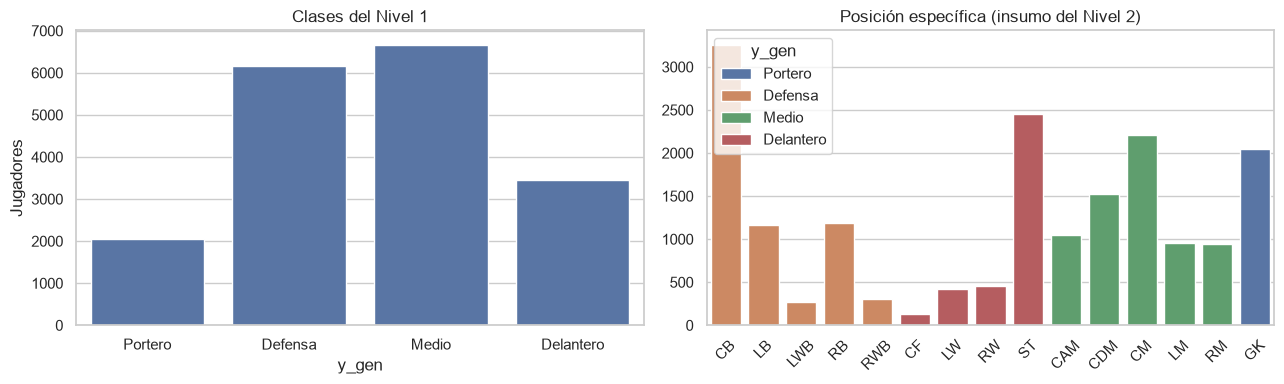

In [2]:
conteo = df["y_gen"].value_counts().reindex(ORDEN)
porcentaje = (conteo / conteo.sum() * 100).round(1)
display(pd.DataFrame({"jugadores": conteo, "%": porcentaje}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.barplot(x=conteo.index, y=conteo.values, order=ORDEN, ax=axes[0])
axes[0].set_title("Clases del Nivel 1")
axes[0].set_ylabel("Jugadores")

por_pos = (df.groupby(["y_gen", "posicion_principal"]).size()
             .reset_index(name="n"))
sns.barplot(data=por_pos, x="posicion_principal", y="n", hue="y_gen",
            hue_order=ORDEN, dodge=False, ax=axes[1])
axes[1].set_title("Posición específica (insumo del Nivel 2)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Lectura:** si hay desbalance marcado, conviene usar partición estratificada y evaluar con
*macro-F1* o recall por clase, no solo con exactitud global. En la gráfica de la derecha se
ve cuántos ejemplos tendrá cada submodelo del Nivel 2; las posiciones con pocos jugadores
serán las más difíciles de aprender.

## 2. Ceros estructurales

In [3]:
compuestas = [c for c in ["pace", "shooting", "passing", "dribbling", "defending", "physic"] if c in df.columns]
portero_cols = [c for c in metricas if c.startswith("goalkeeping_")]

ceros_compuestas = (df[compuestas] == 0).groupby(df["y_gen"]).mean().reindex(ORDEN).round(3)
ceros_portero = (df[portero_cols] == 0).groupby(df["y_gen"]).mean().reindex(ORDEN).round(3)

print("Proporción de ceros en las métricas compuestas (pace, shooting, ...):")
display(ceros_compuestas)
print("Proporción de ceros en goalkeeping_*:")
display(ceros_portero)

Proporción de ceros en las métricas compuestas (pace, shooting, ...):


,pace,shooting,passing,dribbling,defending,physic
y_gen,,,,,,
Portero,1.0,1.0,1.0,1.0,1.0,1.0
Defensa,0.0,0.0,0.0,0.0,0.0,0.0
Medio,0.0,0.0,0.0,0.0,0.0,0.0
Delantero,0.0,0.0,0.0,0.0,0.0,0.0


Proporción de ceros en goalkeeping_*:


,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,goalkeeping_speed
y_gen,,,,,,
Portero,0.0,0.0,0.0,0.0,0.0,0.0
Defensa,0.0,0.0,0.0,0.0,0.0,1.0
Medio,0.0,0.0,0.0,0.0,0.0,1.0
Delantero,0.0,0.0,0.0,0.0,0.0,1.0


**Lectura:** si los porteros concentran los ceros de las métricas de campo, y los jugadores de
campo los de `goalkeeping_*`, el `fillna(0)` solo está rellenando nulos estructurales. En el
Nivel 2 habrá que descartar las columnas `goalkeeping_*` de los bloques de campo, porque ahí
no aportan nada.

## 3. ¿Qué métricas distinguen a cada posición?

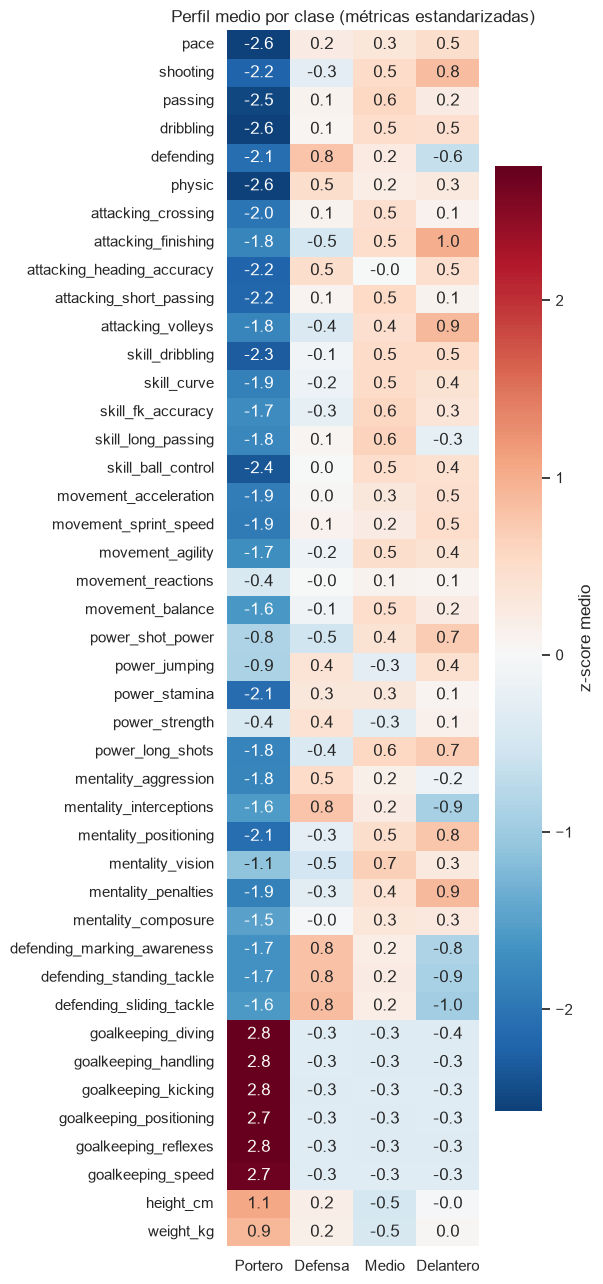

In [4]:
Z = pd.DataFrame(StandardScaler().fit_transform(df[metricas]), columns=metricas)
perfil = Z.groupby(df["y_gen"].values).mean().reindex(ORDEN).T

fig, ax = plt.subplots(figsize=(6, 13))
sns.heatmap(perfil, cmap="RdBu_r", center=0, annot=True, fmt=".1f", ax=ax, cbar_kws={"label": "z-score medio"})
ax.set_title("Perfil medio por clase (métricas estandarizadas)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Lectura:** las filas con colores opuestos entre clases son las que más separan. Las filas
casi blancas en todas las columnas aportan poco al Nivel 1 y son candidatas a descartarse.

## 4. Correlaciones entre métricas

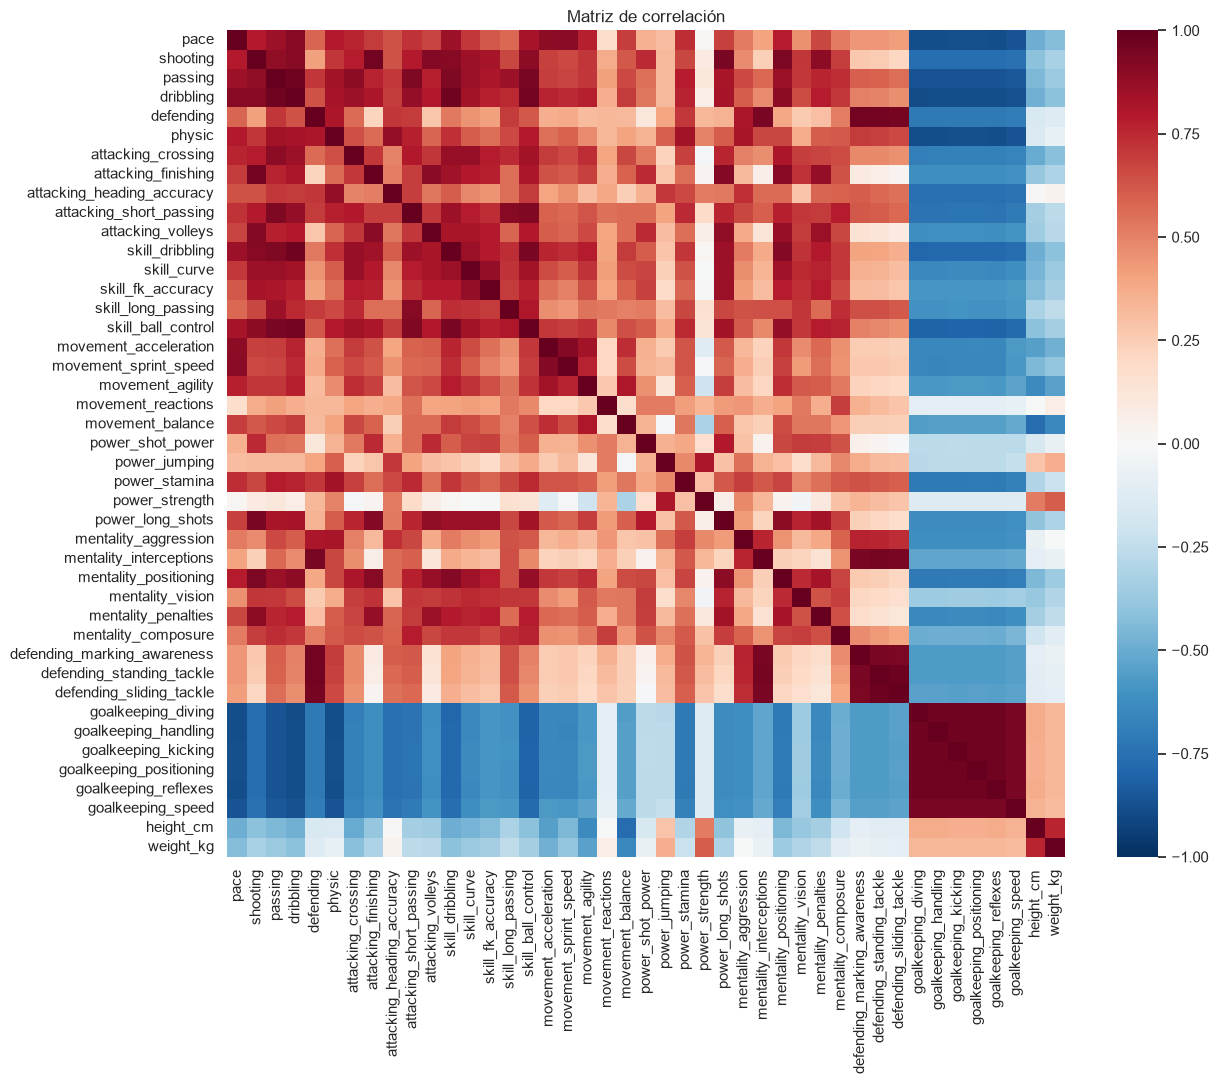

Pares con |correlación| > 0.90: 47


,metrica_a,metrica_b,corr
1453,defending_standing_tackle,defending_sliding_tackle,0.979
1544,goalkeeping_diving,goalkeeping_reflexes,0.974
1541,goalkeeping_diving,goalkeeping_handling,0.973
1587,goalkeeping_handling,goalkeeping_reflexes,0.973
1673,goalkeeping_positioning,goalkeeping_reflexes,0.972
1586,goalkeeping_handling,goalkeeping_positioning,0.972
1543,goalkeeping_diving,goalkeeping_positioning,0.972
140,dribbling,skill_dribbling,0.971
89,passing,dribbling,0.970
1542,goalkeeping_diving,goalkeeping_kicking,0.970


In [5]:
corr = df[metricas].corr()

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True)
ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()

triangulo = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pares = (triangulo.stack().rename("corr").reset_index()
         .rename(columns={"level_0": "metrica_a", "level_1": "metrica_b"}))
pares["abs"] = pares["corr"].abs()
print("Pares con |correlación| > 0.90:", int((pares["abs"] > 0.90).sum()))
display(pares.sort_values("abs", ascending=False).head(15).drop(columns="abs").round(3))

**Lectura:** muchas métricas altamente correlacionadas indican redundancia. Es la motivación
para usar Fisher en el Nivel 1 y SFS en el Nivel 2.

## 5. ¿Se separan las clases? PCA vs. Fisher (LDA)

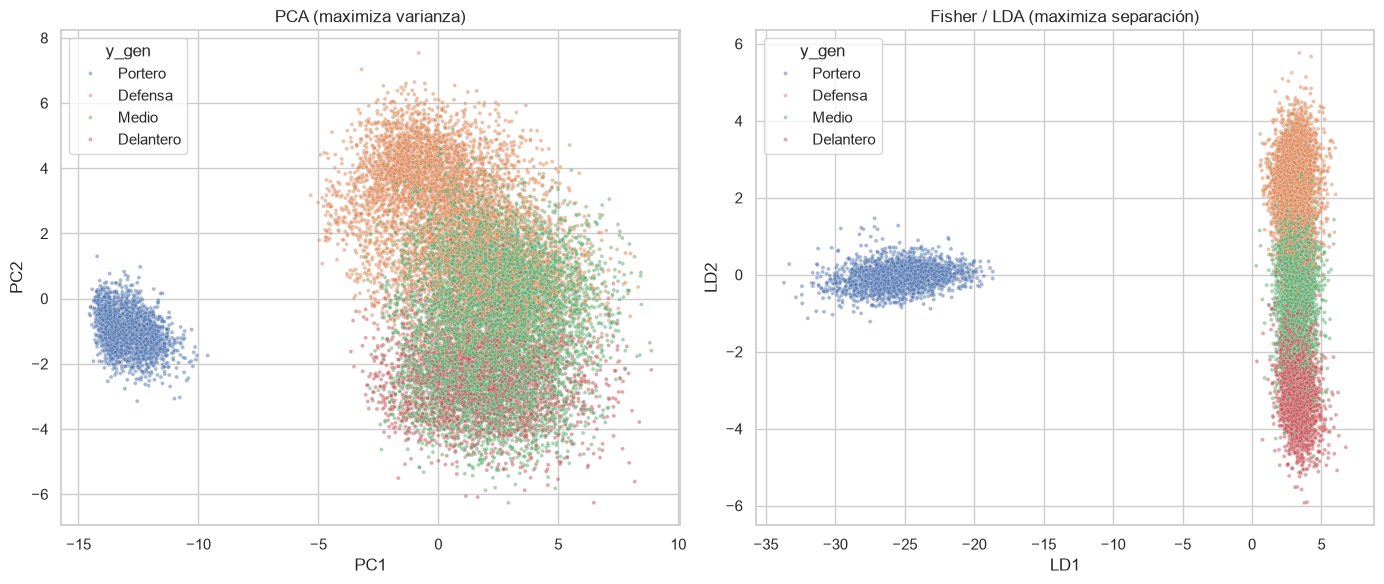

Varianza explicada por PC1 y PC2: [0.592 0.135]
Razón de separación por componente LDA: [0.954 0.037 0.009]


In [6]:
X = StandardScaler().fit_transform(df[metricas])
y = df["y_gen"]

pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)

lda = LinearDiscriminantAnalysis(n_components=3).fit(X, y)
X_lda = lda.transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, E, titulo, ejes in [
    (axes[0], X_pca, "PCA (maximiza varianza)", ("PC1", "PC2")),
    (axes[1], X_lda, "Fisher / LDA (maximiza separación)", ("LD1", "LD2")),
]:
    sns.scatterplot(x=E[:, 0], y=E[:, 1], hue=y, hue_order=ORDEN, s=8, alpha=0.5, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel(ejes[0])
    ax.set_ylabel(ejes[1])

plt.tight_layout()
plt.show()

print("Varianza explicada por PC1 y PC2:", pca.explained_variance_ratio_.round(3))
print("Razón de separación por componente LDA:", lda.explained_variance_ratio_.round(3))

**Lectura:** esta gráfica es un anticipo del Nivel 1. Si en LDA las 4 nubes se distinguen
mejor que en PCA, la elección de Fisher está justificada. Las zonas donde se traslapan
(típicamente Medio con Defensa y con Delantero) son donde esperamos los errores del clasificador.

## Conclusiones

- **Balance de clases:** desbalance moderado. Medio (36%) y Defensa (34%) dominan, mientras que Delantero (18.8%) y Portero (11.1%) están subrepresentados. Habrá que usar partición estratificada y métricas por clase.
- **Nulos estructurales:** confirmados. Los nulos corresponden solo a las métricas de campo en porteros (y a la métrica de portero en jugadores de campo), por lo que el `fillna(0)` no está inventando información de jugadores reales.
- **Métricas más discriminantes:**
  - Portero: los `goalkeeping_*` (≈ +2.7 contra −0.3 en el resto) lo aíslan casi por sí solos; estatura y peso también aportan (+1.1 y +0.9).
  - Defensa: `defending_*` (marking, standing y sliding tackle ≈ +0.8, contra −0.8 a −1.0 en Delantero) e `interceptions` (+0.8 vs −0.9).
  - Delantero: `finishing` (+1.0), `penalties` y `volleys` (+0.9), `positioning` (+0.8), `shot_power` y `long_shots` (+0.7).
  - Medio: perfil más tenue, con `vision` (+0.7) y los pases (+0.5 a +0.6). Ninguna métrica lo distingue con fuerza; queda intermedio entre Defensa y Delantero.
- **Redundancia entre métricas:** 47 pares con |r| > 0.90. Los grupos más claros son los `goalkeeping_*` (≈ 0.97 entre sí), los dos tackles (0.979) y las métricas compuestas con sus componentes detallados (`dribbling` ↔ `skill_dribbling` 0.971, `defending` ↔ `defending_standing_tackle` 0.968). Conviene usar compuestas o detalladas, no ambas.
- **Separabilidad (PCA vs. LDA):** los porteros forman un clúster totalmente aislado en ambos métodos. Entre jugadores de campo, las clases se ordenan sobre un eje defensivo-ofensivo (Defensa arriba, Medio al centro, Delantero abajo) y Medio se solapa con las otras dos. Se esperan errores en Defensa↔Medio y Medio↔Delantero, y pocos en Defensa↔Delantero.